<a href="https://colab.research.google.com/github/patilaniket582/ML36/blob/main/Experiment3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_curve, auc

In [4]:
url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"
df = pd.read_csv(url)
cols = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]
df[cols] = df[cols].replace(0, np.nan).fillna(df[cols].median())
X = df.drop("Outcome", axis=1)
y = df["Outcome"]
print(df.head())

   Pregnancies  Glucose  BloodPressure  SkinThickness  Insulin   BMI  \
0            6    148.0           72.0           35.0     30.5  33.6   
1            1     85.0           66.0           29.0     30.5  26.6   
2            8    183.0           64.0           23.0     30.5  23.3   
3            1     89.0           66.0           23.0     94.0  28.1   
4            0    137.0           40.0           35.0    168.0  43.1   

   DiabetesPedigreeFunction  Age  Outcome  
0                     0.627   50        1  
1                     0.351   31        0  
2                     0.672   32        1  
3                     0.167   21        0  
4                     2.288   33        1  


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)
model = LogisticRegression()
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

Accuracy: 0.7077922077922078


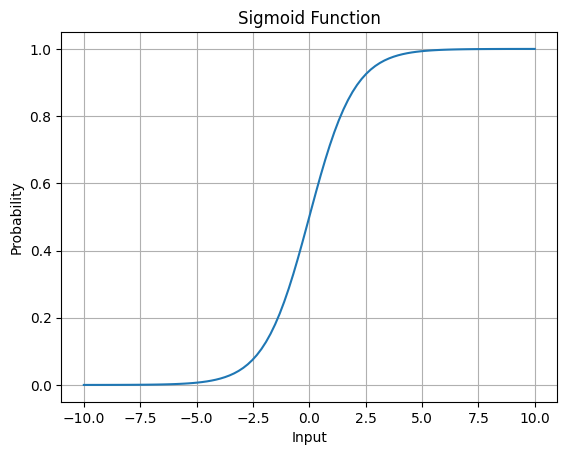

In [10]:
z = np.linspace(-10, 10, 100)
plt.plot(z, 1 / (1 + np.exp(-z)))
plt.title("Sigmoid Function")
plt.xlabel("Input")
plt.ylabel("Probability")
plt.grid()
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


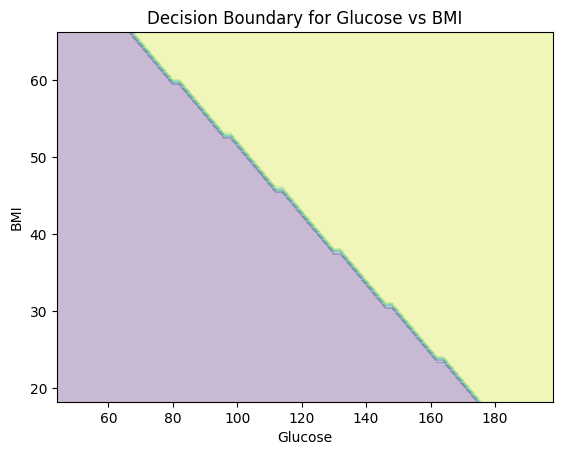

In [14]:
X2 = df[["Glucose", "BMI"]]
a, b = np.meshgrid(
    np.arange(X2.Glucose.min(), X2.Glucose.max(), 2),
    np.arange(X2.BMI.min(), X2.BMI.max(), 1)
)

sc2 = StandardScaler()
X2_scaled = sc2.fit_transform(X2)
m2 = LogisticRegression().fit(X2_scaled, y)

grid = sc2.transform(np.c_[a.ravel(), b.ravel()])
pred = m2.predict(grid).reshape(a.shape)

plt.contourf(a, b, pred, alpha=0.3)
plt.title("Decision Boundary for Glucose vs BMI")
plt.xlabel("Glucose")
plt.ylabel("BMI")
plt.show()

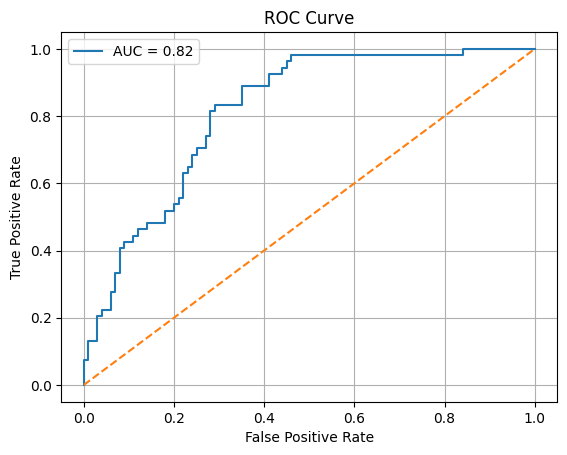

AUC: 0.8151851851851852


In [16]:
prob = model.predict_proba(X_test)[:, 1]
fpr, tpr, _ = roc_curve(y_test, prob)
score = auc(fpr, tpr)

plt.plot(fpr, tpr, label="AUC = %.2f" % score)
plt.plot([0, 1], [0, 1], "--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.grid()
plt.show()

print("AUC:", score)